In [2]:
import time
import numpy as np
import daq
from daq.daq import DAQ
from daq.shared_ring_buffer import SharedRingBuffer
from daq.acquisition import AcquisitionThread


daq = DAQ()

daq.start_scan(
    low_channel=0,
    high_channel=3,
    sample_rate=1000,
    buffer_size=10000
)

import time
time.sleep(1)

samples, overflow = (
    daq.read_new_samples()
)

print(samples.shape)
print(samples[:5])

Max scan rate : 500000.0 Hz
Min scan rate : 0.01629814505956558 Hz
Resolution : 12 bits
Pacer : True
(4000, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [1]:
import time
import numpy as np
import daq
from daq.daq import DAQ
from daq.shared_ring_buffer import SharedRingBuffer
from daq.acquisition import AcquisitionThread


# --------------------------------------------------
# DAQ
# --------------------------------------------------

daq = DAQ()

daq.start_scan(
    channel=0,
    sample_rate=1000,
    buffer_size=10000
)

print("DAQ started")


# --------------------------------------------------
# Shared buffer
# --------------------------------------------------

buffer = SharedRingBuffer(
    n_channels=1,
    capacity=100000
)


# --------------------------------------------------
# Acquisition thread
# --------------------------------------------------

acq = AcquisitionThread(
    daq=daq,
    buffer=buffer,
    n_channels=1
)

acq.start()

print("Acquisition thread started")


# --------------------------------------------------
# Monitoring loop
# --------------------------------------------------

try:

    while True:

        last = buffer.get_last(10)

        if len(last):

            mean = np.mean(last[:, 0])

            current_index = (
                buffer.sample_index
            )

            print(
                f"samples={current_index:10d}   "
                f"mean={mean:8.4f} V   "
                f"overflow={acq.overflow_count}"
            )

        time.sleep(1)

except KeyboardInterrupt:

    print("\nStopping...")

    acq.stop()

    daq.stop_scan()

    daq.close()

    print("Done.")

Max scan rate : 500000.0 Hz
Min scan rate : 0.01629814505956558 Hz
Resolution : 12 bits
Pacer : True
DAQ started
Acquisition thread started
samples=      1000   mean=  0.2296 V   overflow=0
samples=      2001   mean=  0.2301 V   overflow=0
samples=      3002   mean=  0.2296 V   overflow=0
samples=      4003   mean=  0.2301 V   overflow=0
samples=      5002   mean=  0.2296 V   overflow=0
samples=      6003   mean=  0.2296 V   overflow=0
samples=      7004   mean=  0.2301 V   overflow=0
samples=      8004   mean=  0.2296 V   overflow=0
samples=      9004   mean=  0.2296 V   overflow=0
samples=     10005   mean=  0.2296 V   overflow=0
samples=     11005   mean=  0.2301 V   overflow=0
samples=     12005   mean=  0.2301 V   overflow=0
samples=     13005   mean=  0.2301 V   overflow=0
samples=     14006   mean=  0.2301 V   overflow=0
samples=     15007   mean=  0.2296 V   overflow=0
samples=     16007   mean=  0.2306 V   overflow=0

Stopping...
Done.


In [1]:
%matplotlib widget

In [2]:
import daq
import scope

In [3]:

from importlib import reload
reload(daq)
reload(scope)

mydaq = daq.DAQ()

mydaq.start_scan(
    channel=0,
    sample_rate=1000,
    buffer_size=10000
)

Max scan rate : 500000.0 Hz
Min scan rate : 0.01629814505956558 Hz
Resolution : 12 bits
Pacer : True


In [7]:
import matplotlib

print(matplotlib.get_backend())

import ipympl
print(ipympl.__version__)

widget
0.10.0


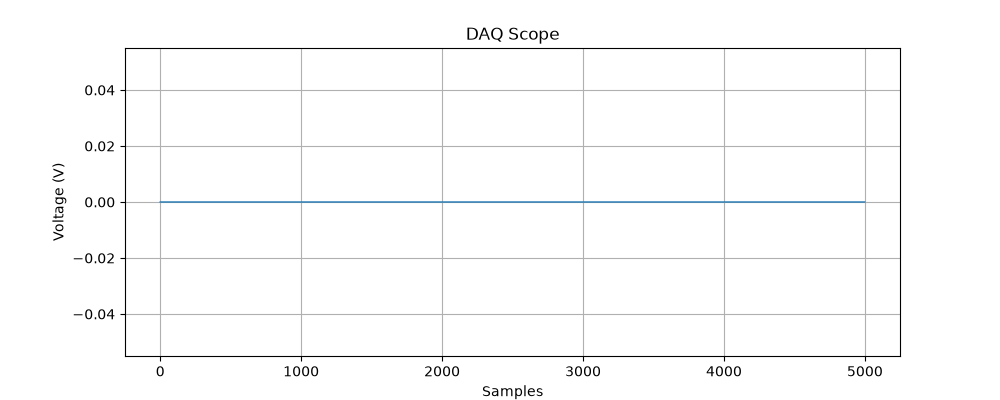

In [4]:
myscope = scope.Scope(
    mydaq,
    duration=5,
    sample_rate=1000
)

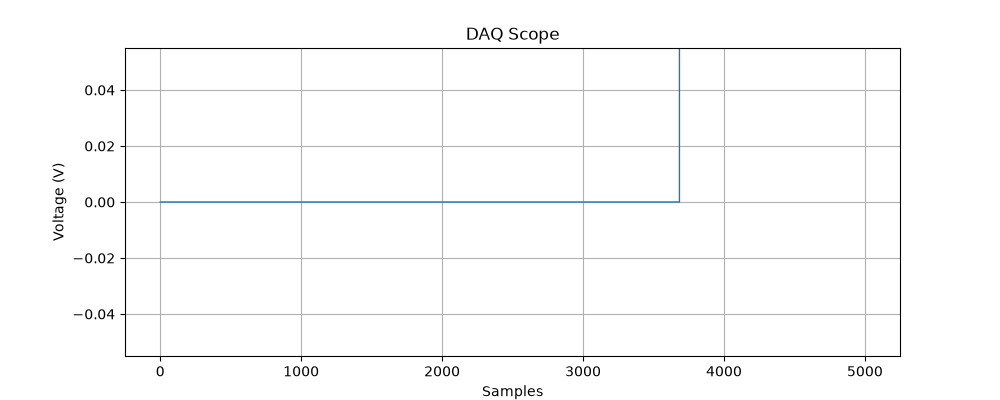

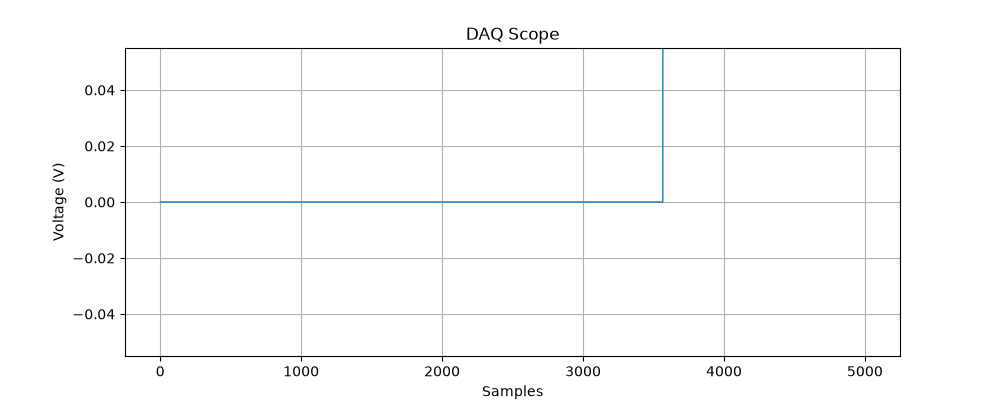

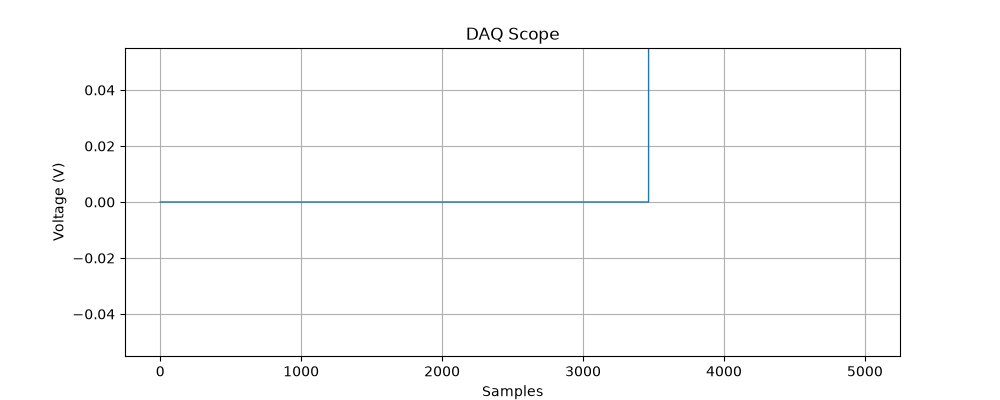

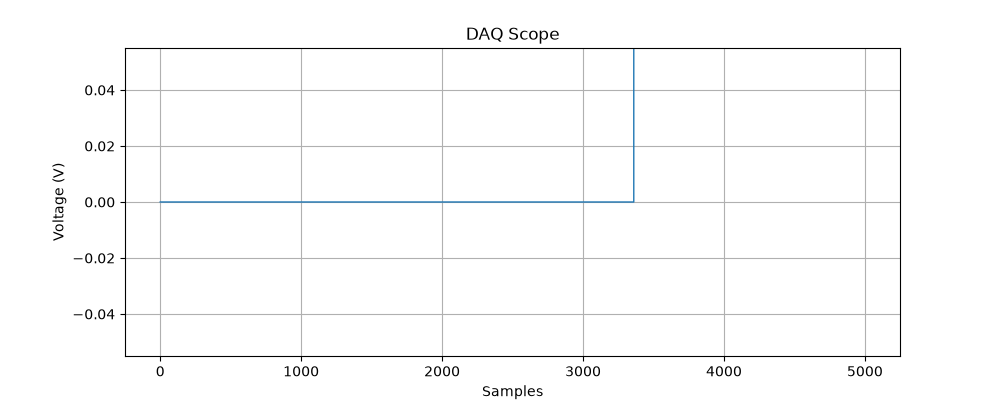

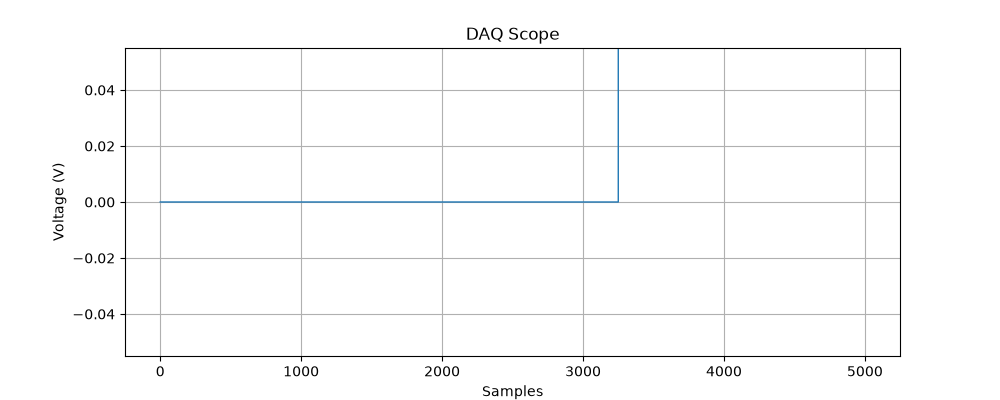

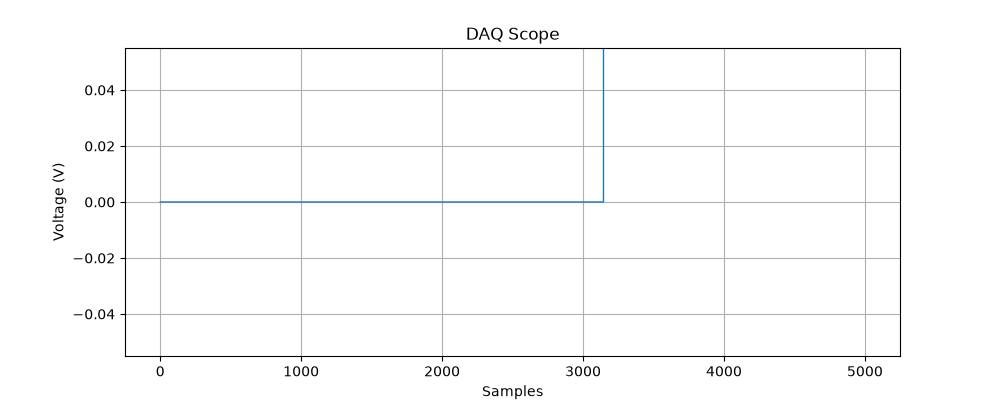

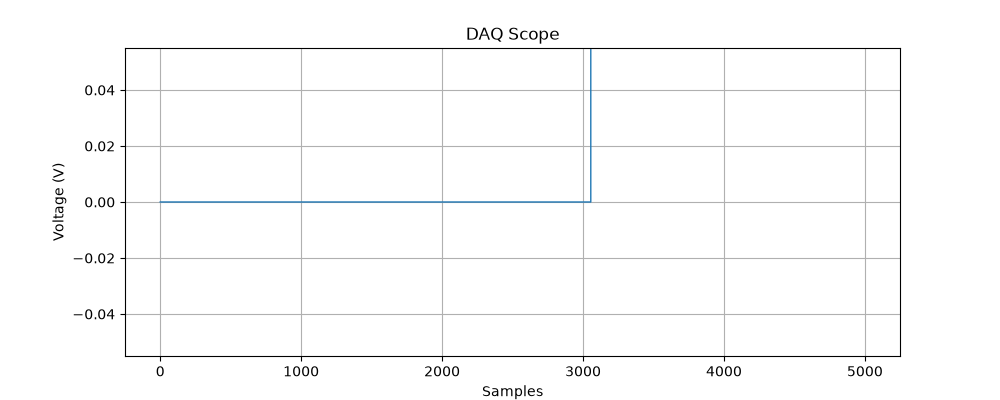

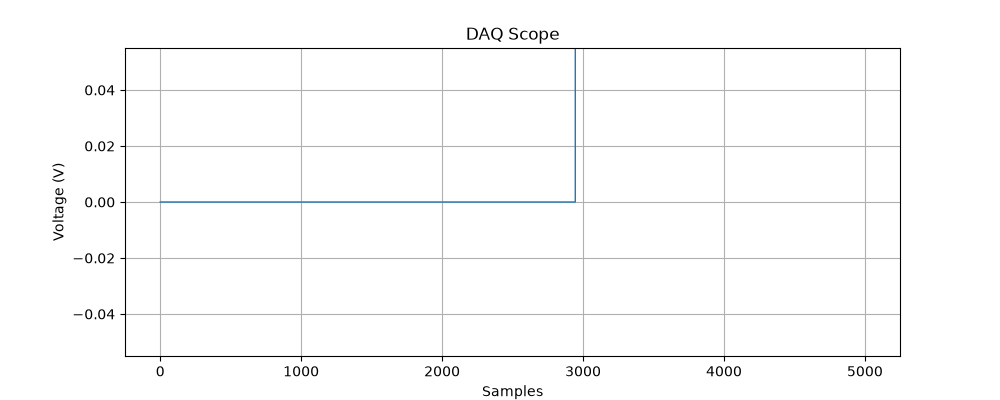

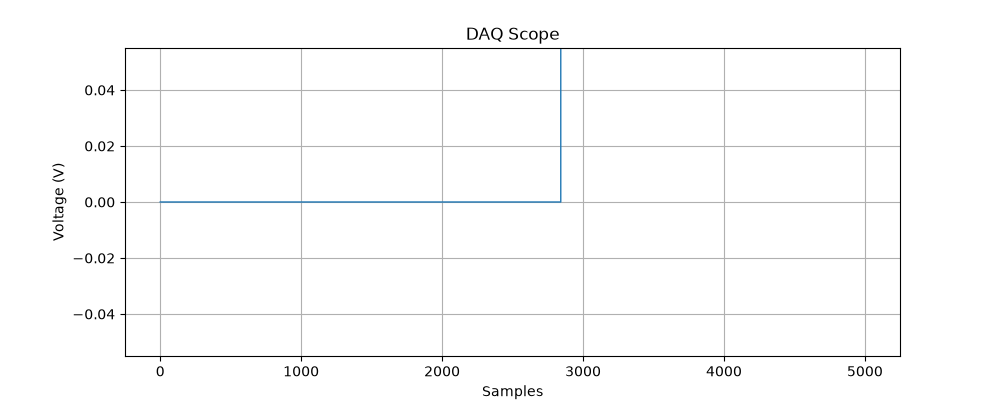

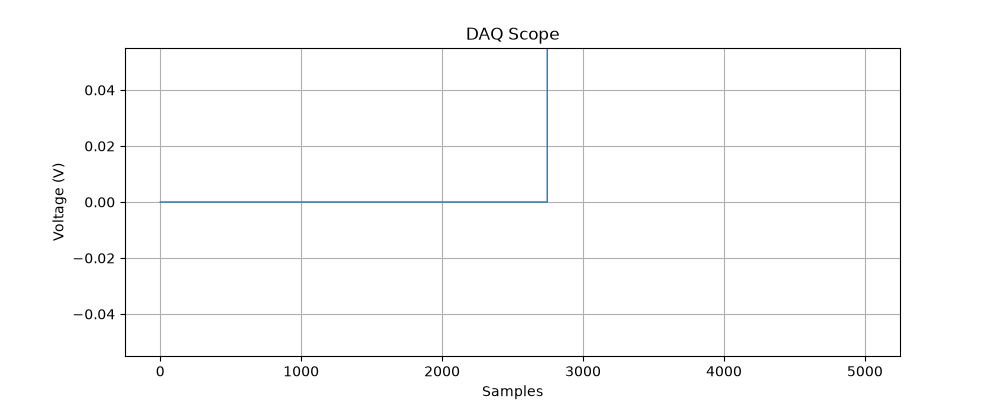

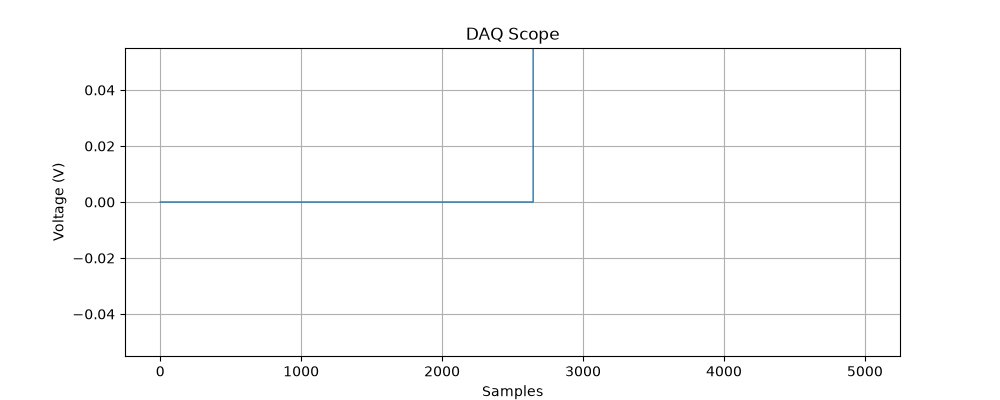

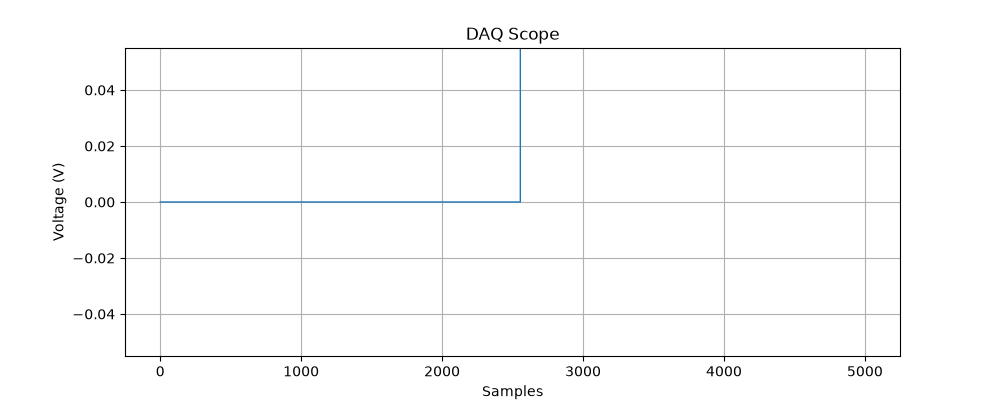

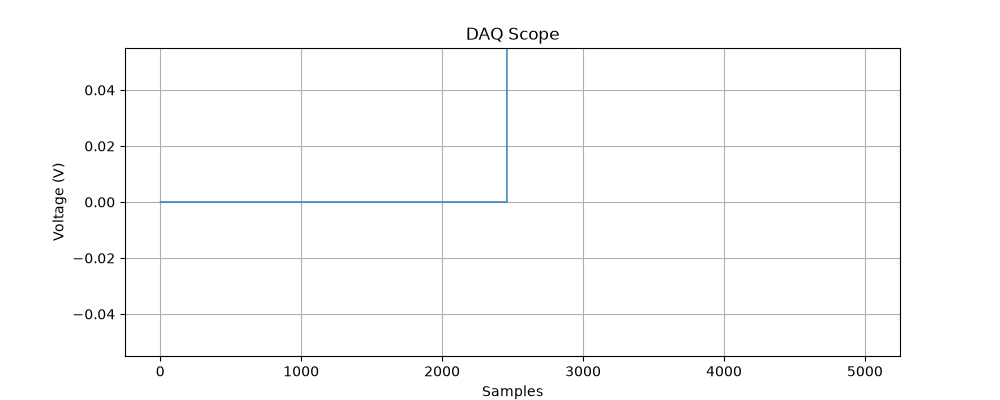

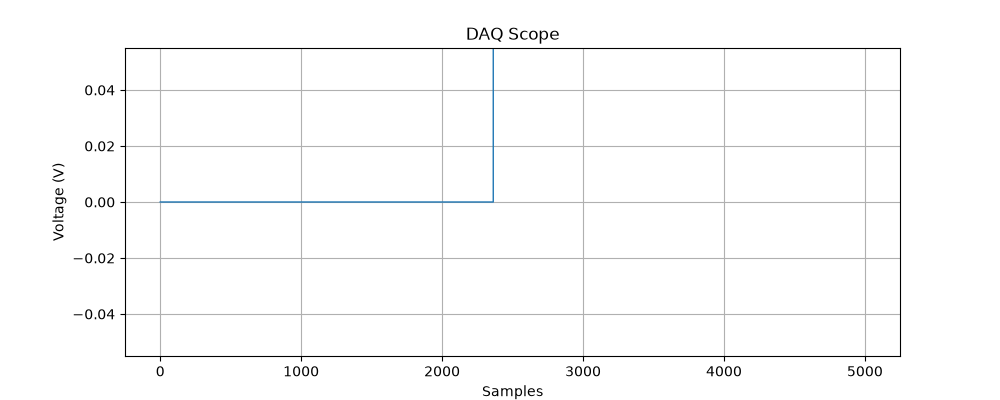

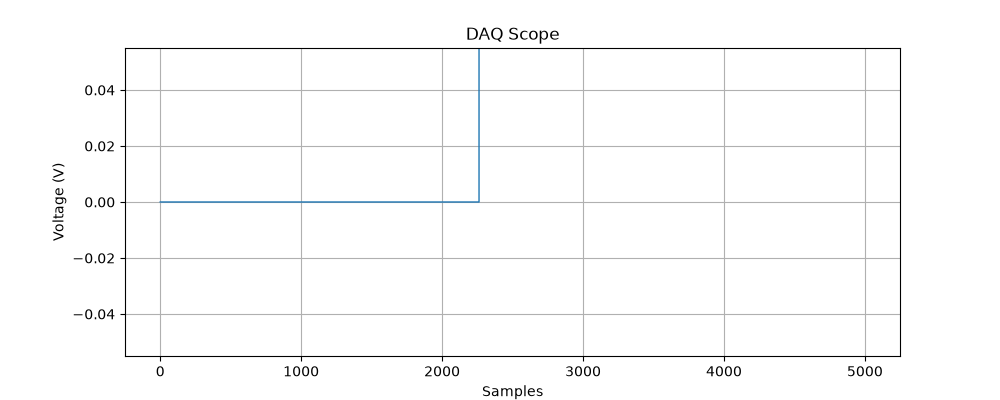

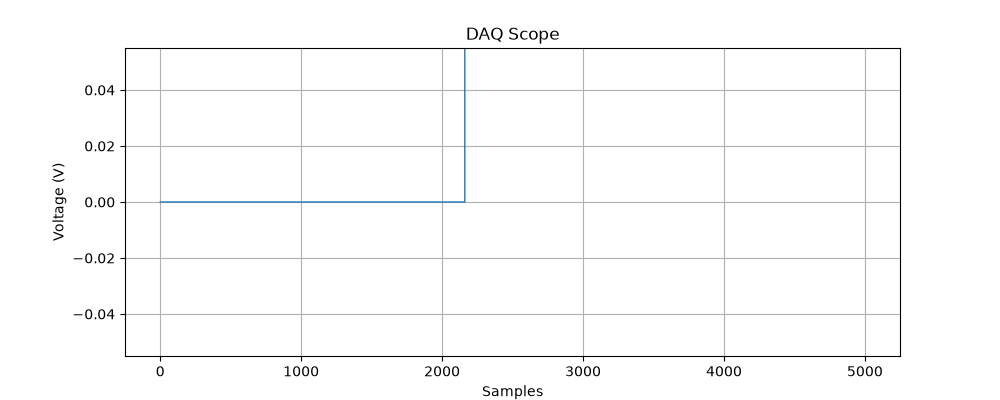

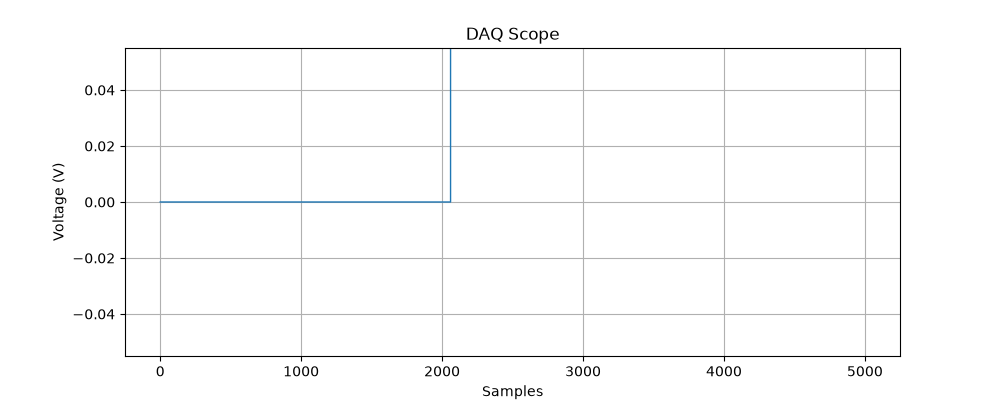

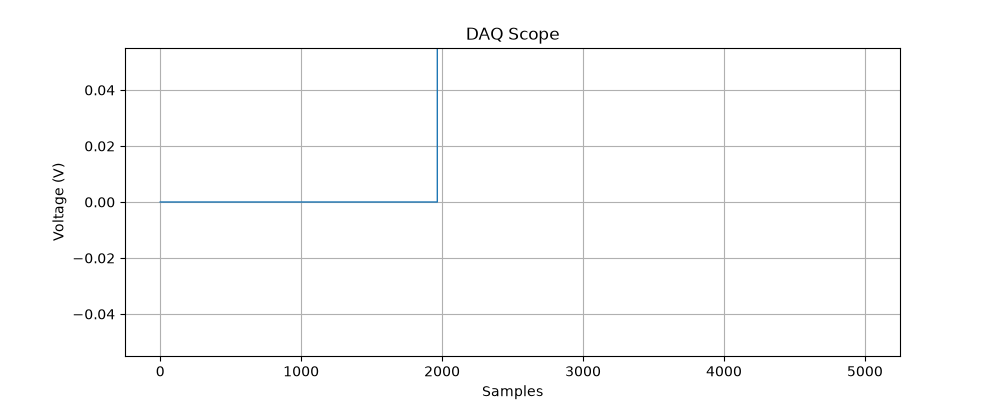

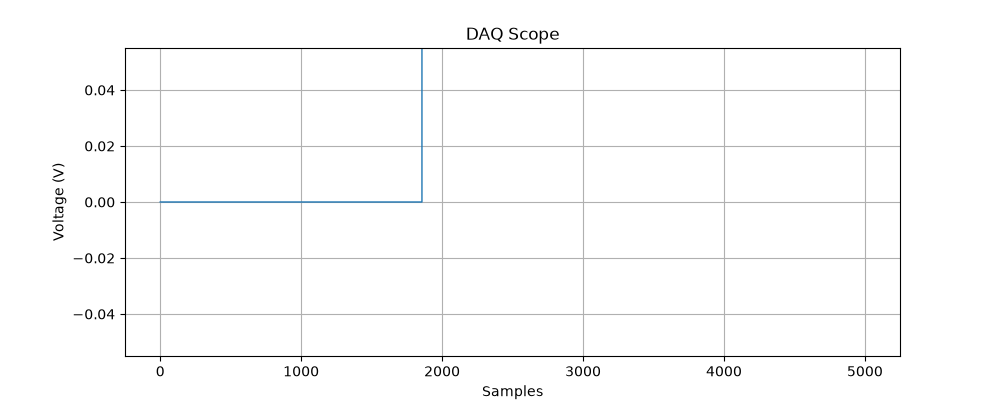

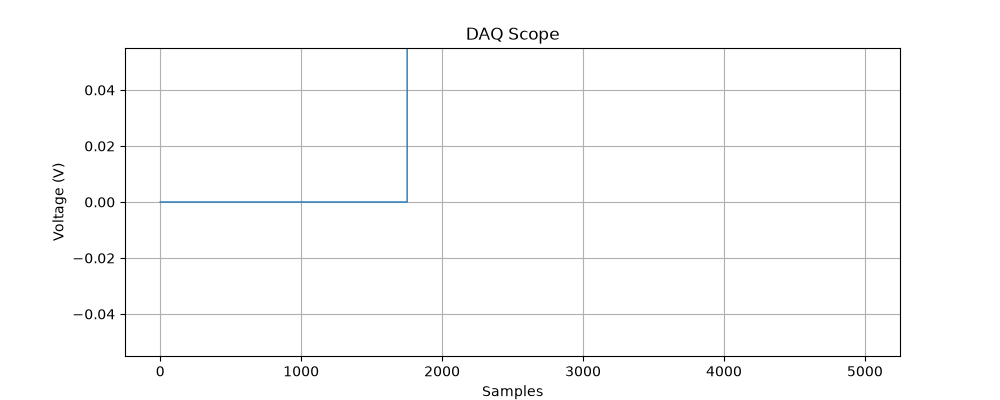

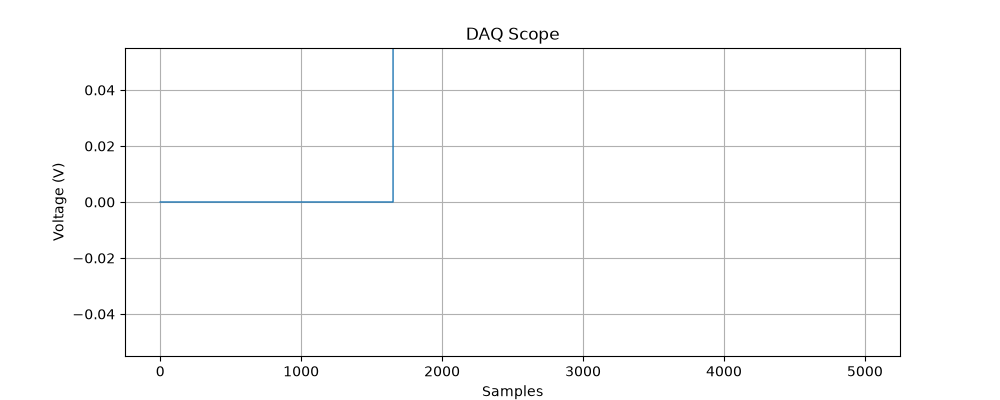

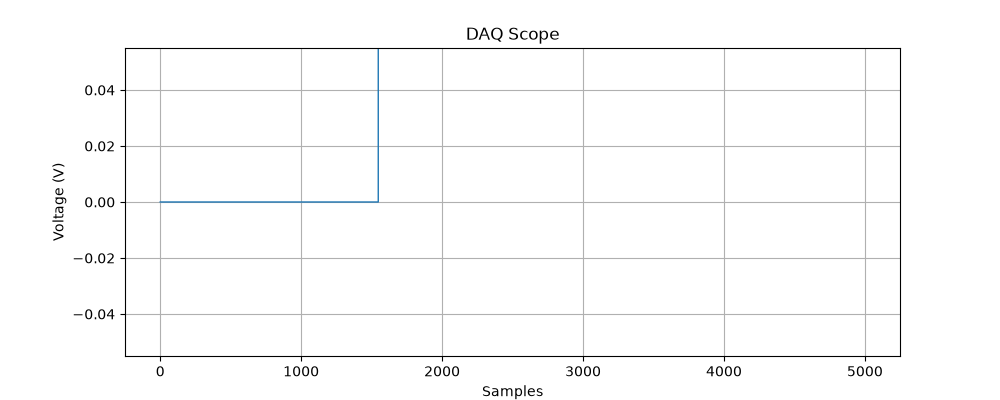

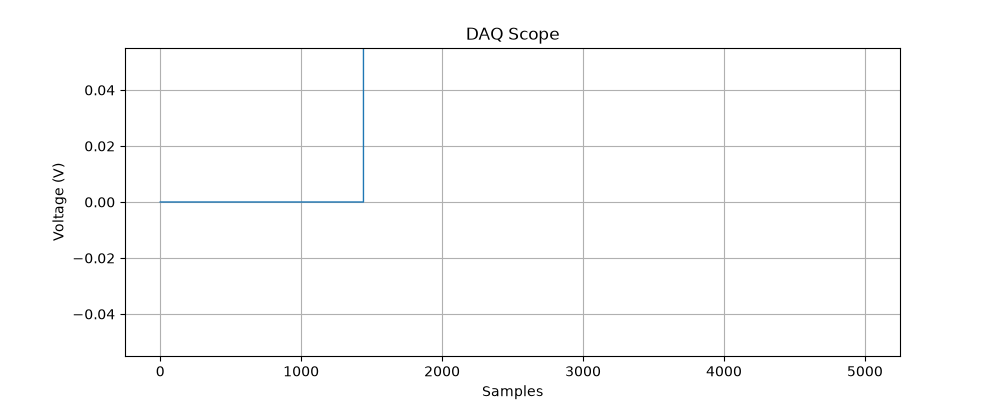

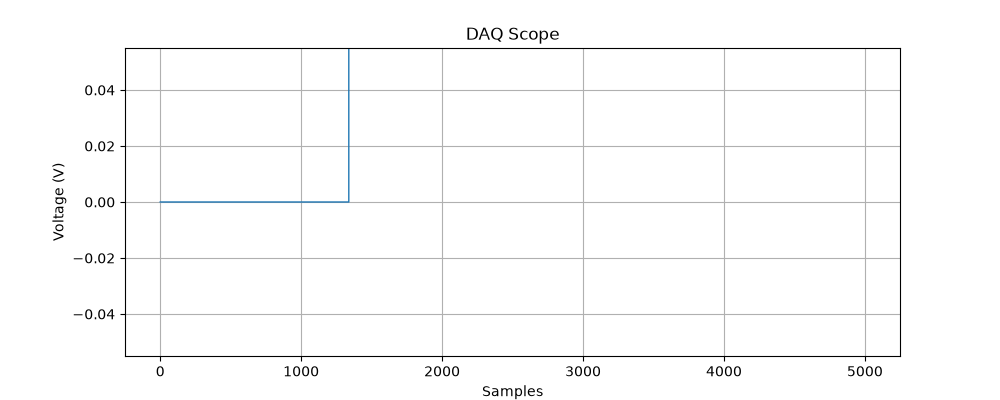

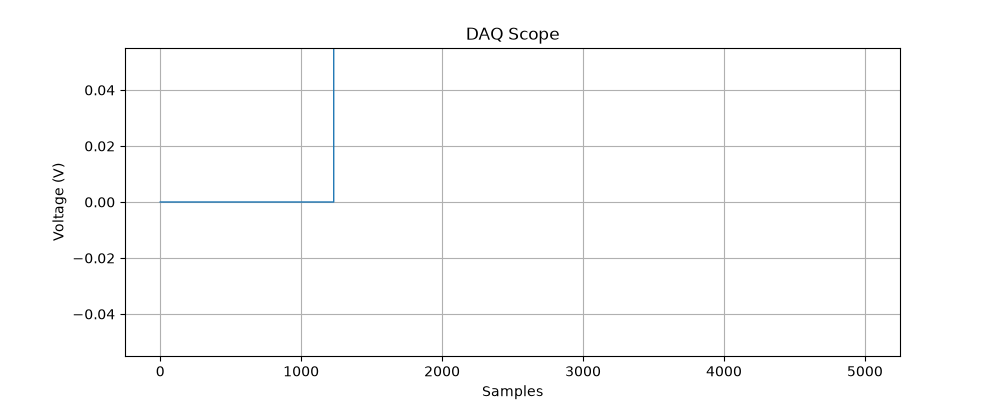

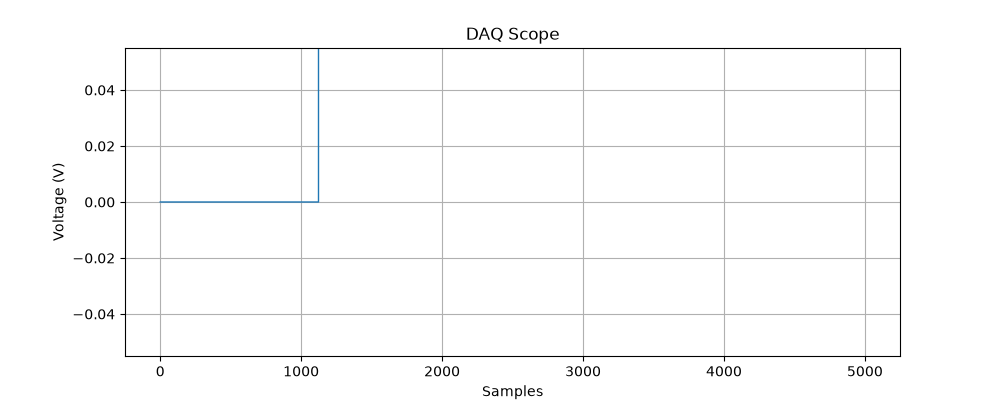

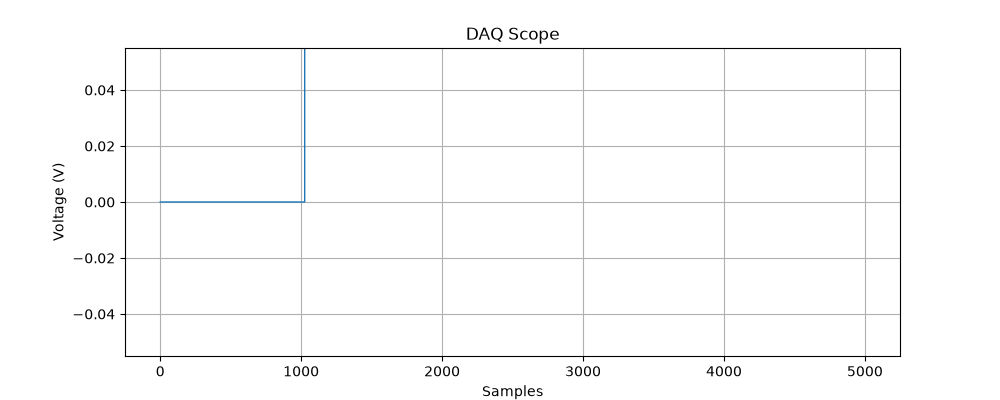

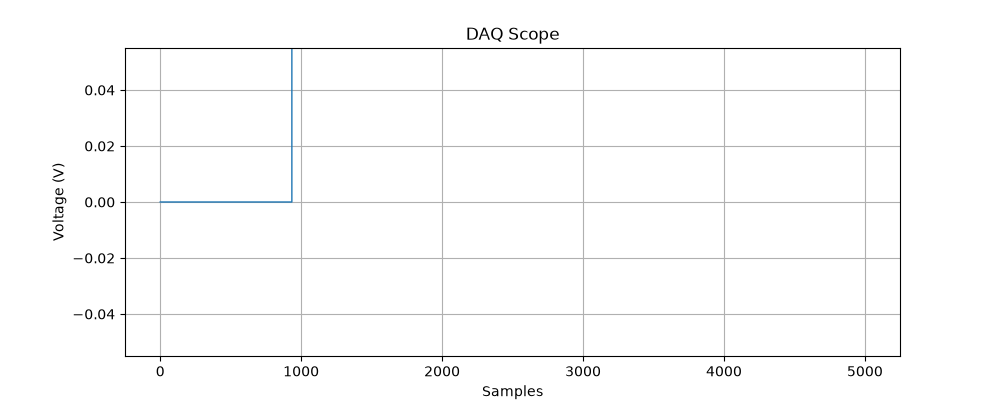

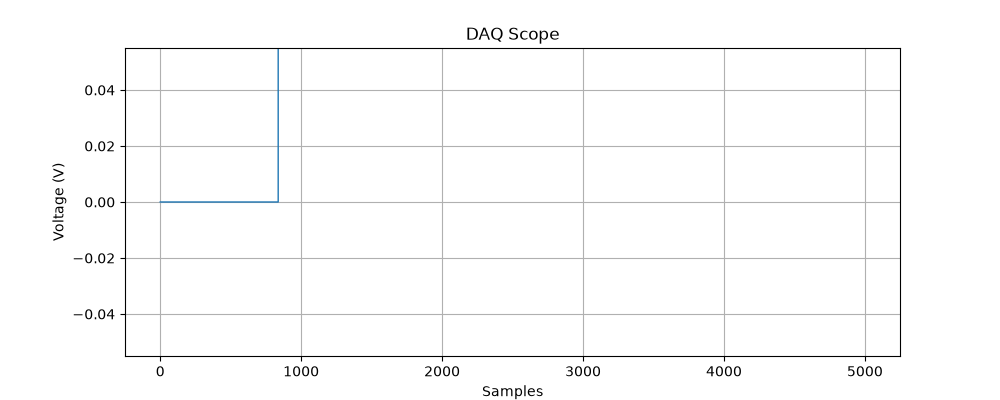

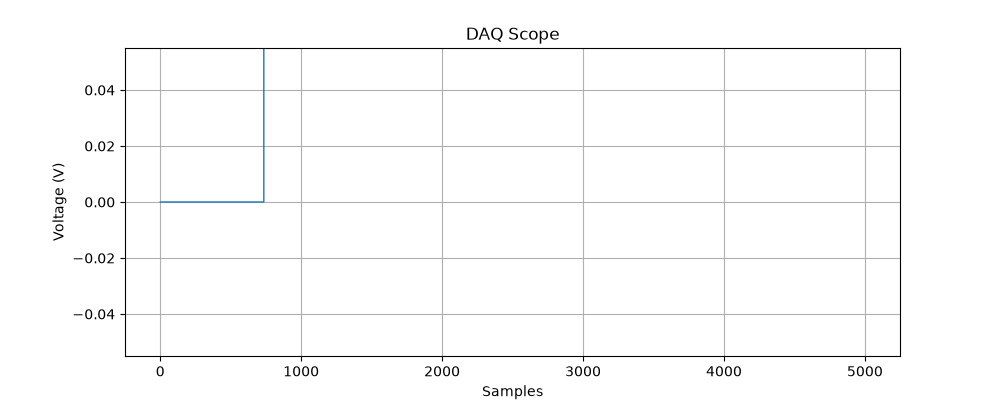

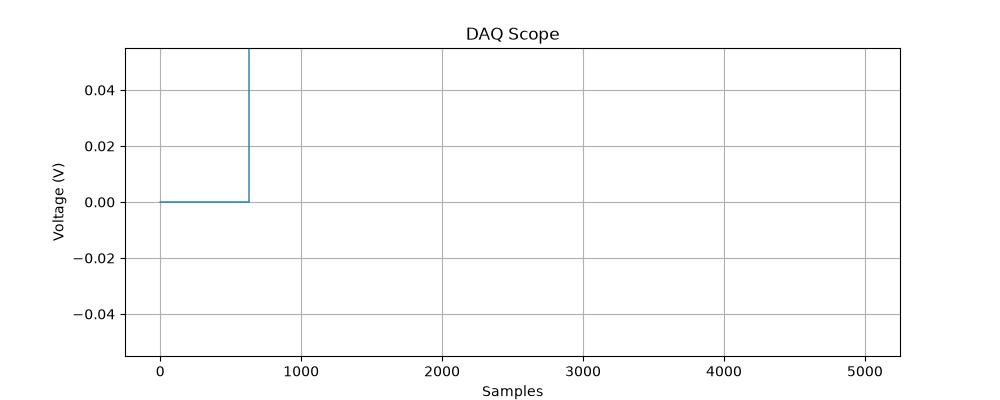

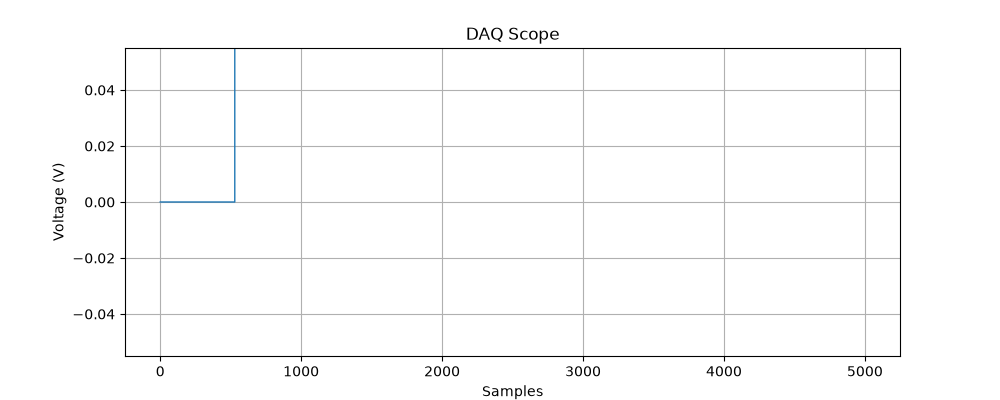

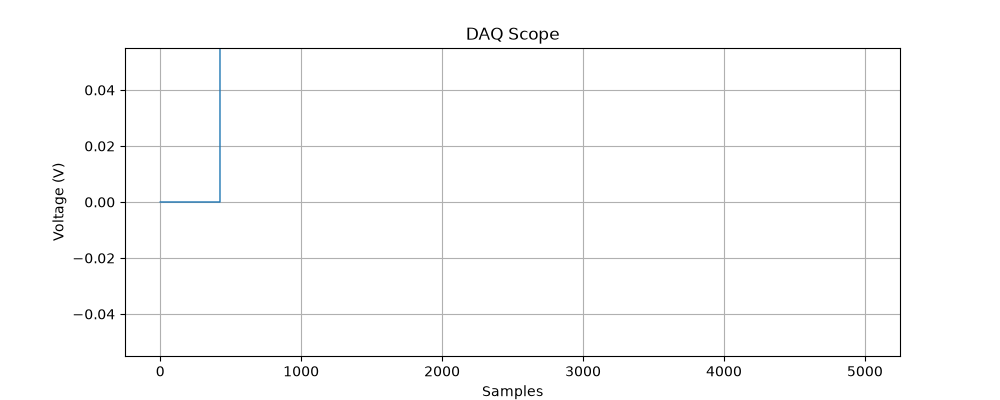

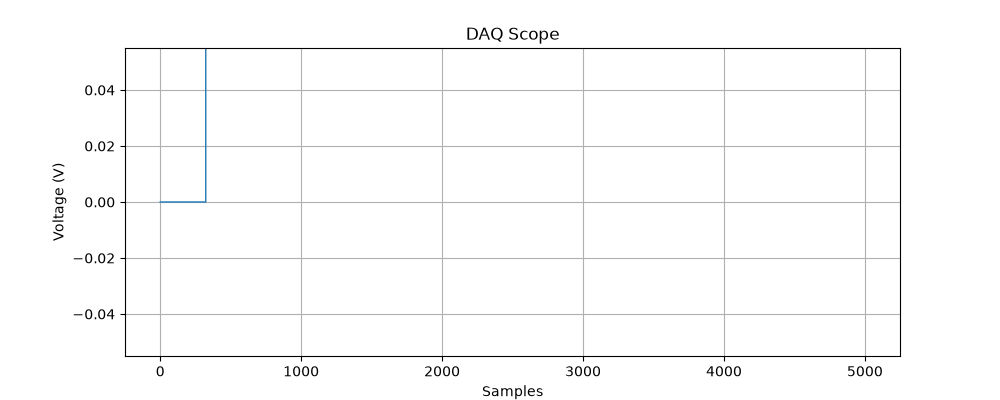

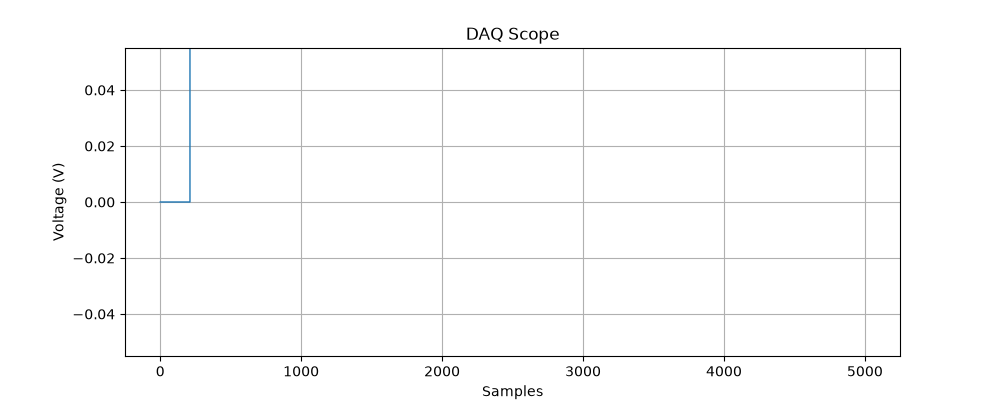

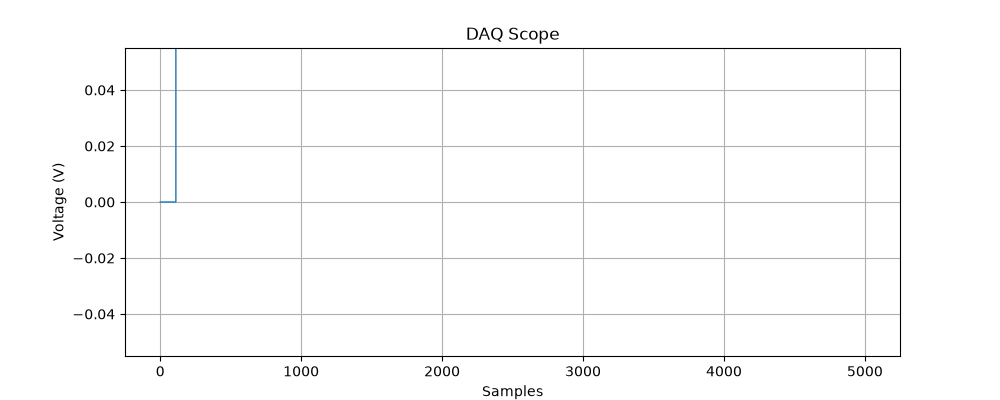

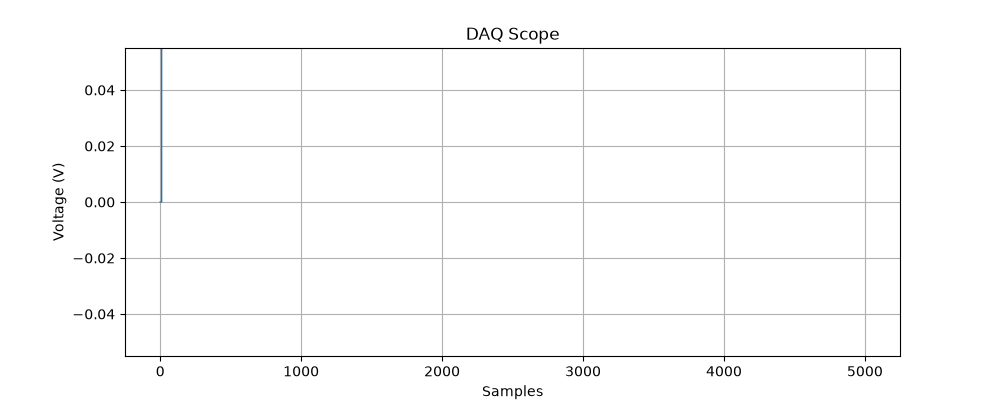

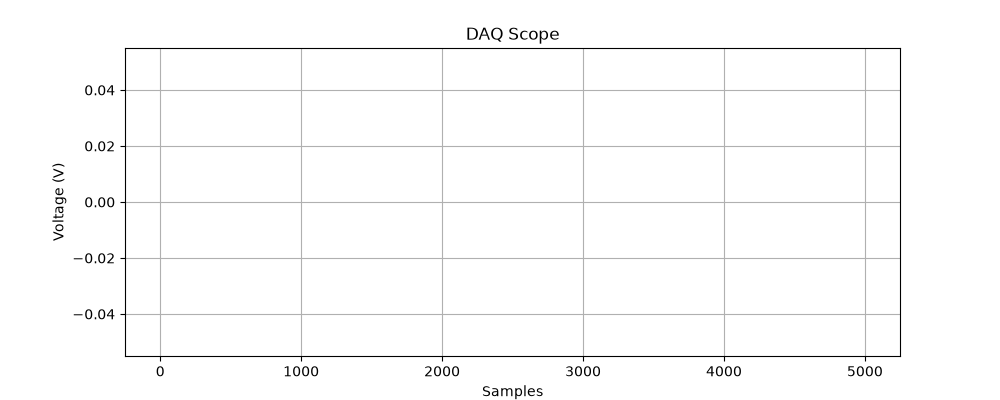

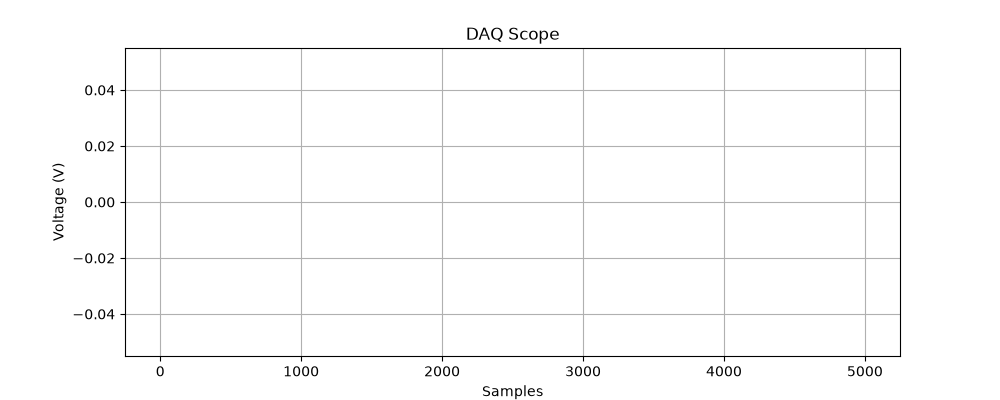

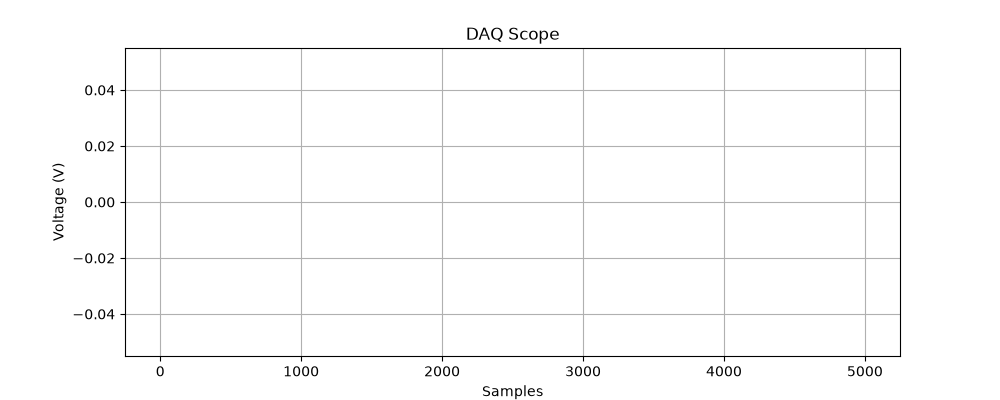

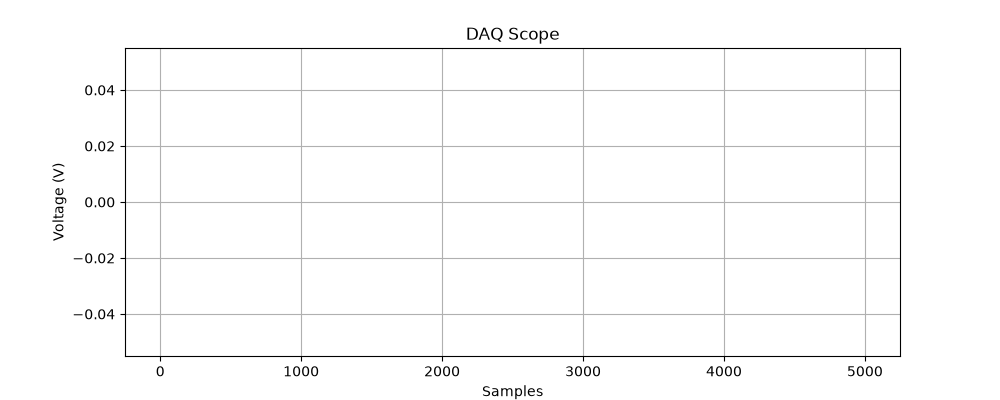

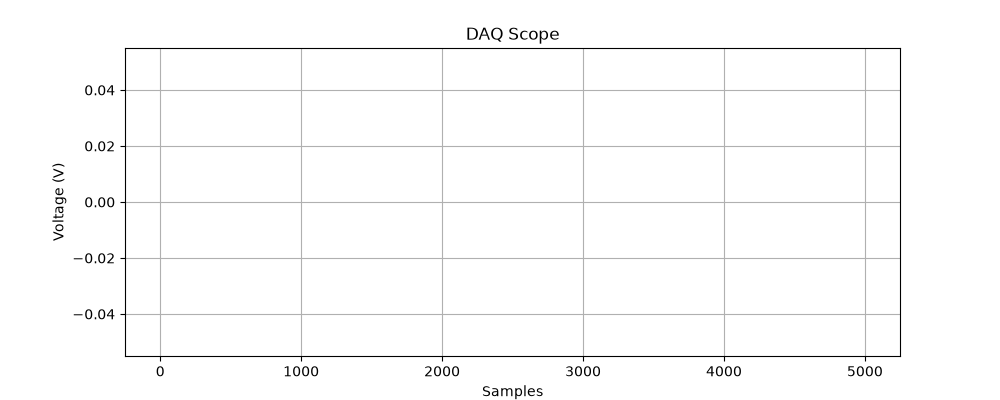

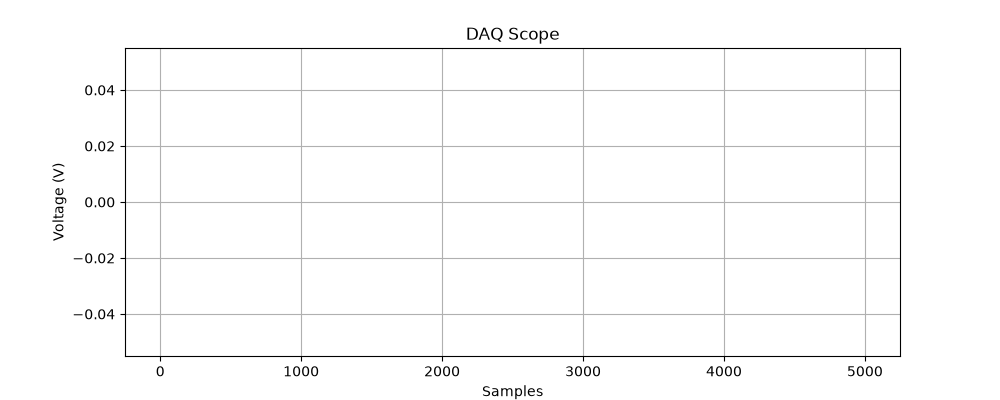

KeyboardInterrupt: 

In [5]:

myscope.run(
    refresh_hz=20
)